In [6]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt
import QuantLib as ql

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension
from Modules.commodity_sector_rotation import CommoditySectorRotation
from Modules.later_1alert_v1 import Later1Alert

In [7]:
# Date range for fetching API s
start = '2022-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")

In [8]:
commodity_sector_rotation = CommoditySectorRotation(
    start_date=start,
    end_date=end,
    api_base_url=API_BASE_URL
)
later_1alert = Later1Alert(API_BASE_URL)

In [9]:
res = later_1alert.execute(start, end)
display(res)

取得件数: 1416
取得件数: 1416
取得件数: 1416


{'alert': False,
 'level': 'LOW',
 'signal': 'SVXY_LEVEL_MOMENTUM',
 'date': '2026-10-23',
 'current': {'svxy_volume_z': 0.28, 'svxy_volume_roc_decile': 7},
 'threshold': {'svxy_volume_z': 3.0, 'svxy_volume_roc_decile': 9}}

In [10]:
df = commodity_sector_rotation.sector_rotation()

取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1416
取得件数: 1419
取得件数: 1419
取得件数: 1419
取得件数: 1419
取得件数: 1418
取得件数: 1419
取得件数: 1321


In [11]:
df

{'all_data':             sector_oil  sector_uranium  sector_gold  sector_silver  \
 date                                                                 
 2021-03-08   79.654730       22.913128    29.437215      37.927520   
 2021-03-09   77.157286       22.883261    30.295607      38.565906   
 2021-03-10   76.035647       23.263010    30.211635      38.763060   
 2021-03-11   78.944934       23.489156    30.482211      39.298170   
 2021-03-12   79.742337       23.604360    30.062348      38.744278   
 ...                ...             ...          ...            ...   
 2026-10-19  199.350006       43.599998    87.139999      82.540001   
 2026-10-20  201.520004       42.779999    85.620003      80.779999   
 2026-10-21  199.520004       43.669998    86.970001      81.680000   
 2026-10-22  200.240005       42.500000    83.849998      78.529999   
 2026-10-23  198.089996       41.330002    81.160004      75.199997   
 
             sector_copper  sector_critical_minerals  benchmark

In [12]:
returns_20d = df["returns_20d"]
returns_60d = df["returns_60d"]
relative_perf = df["relative_perf"]
relative_strength = df["relative_strength"]
latest_20d_rank = df["latest_20d_rank"]
latest_60d_rank = df["latest_60d_rank"]
rotation_score = df["rotation_score"]

In [13]:
print("returns_20d index")
print(returns_20d.iloc[-1].index.tolist())

print()

print("rotation_score index")
print(rotation_score.index.tolist())

print()

print(rotation_score[["score20", "score60"]])

returns_20d index
['oil_20d', 'uranium_20d', 'gold_20d', 'silver_20d', 'copper_20d', 'critical_minerals_20d']

rotation_score index
['oil', 'uranium', 'copper', 'gold', 'critical_minerals', 'silver']

                    score20   score60
oil                0.091706  0.167135
uranium           -0.159618 -0.145721
copper            -0.151318 -0.072942
gold              -0.122025  0.077107
critical_minerals -0.233393 -0.218956
silver            -0.174080  0.012249


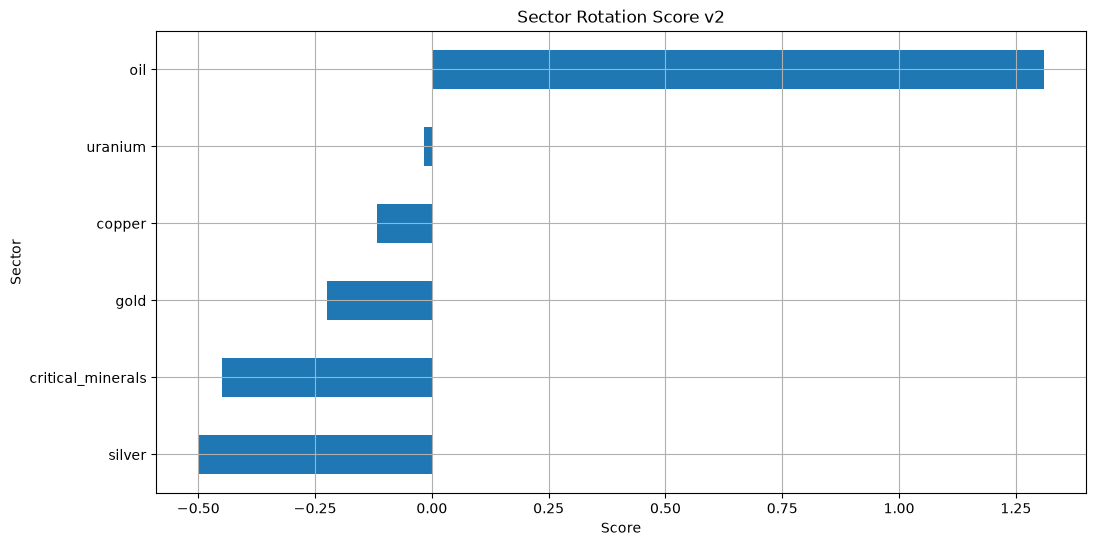

In [14]:
plt.figure(figsize=(12, 6))

(
    rotation_score["rotation_score"]
    .sort_values()
    .plot(kind="barh")
)

plt.title("Sector Rotation Score v2")
plt.xlabel("Score")
plt.ylabel("Sector")
plt.grid(True)
# 保存先のパスを作成
output_path = output_dir / f"sector_rotation_score_v2_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
plt.savefig(output_path)

plt.show()

In [15]:
top_sector = rotation_score.index[0]

print("Top Sector")
print(top_sector)

print()
print("Top 3 Sectors")

rotation_score.head(3)


Top Sector
oil

Top 3 Sectors


,score20,score60,acceleration,z_score20,z_score60,z_acceleration,rotation_score
oil,0.091706,0.167135,-0.075430,1.928390,1.374424,0.236294,1.309968
uranium,-0.159618,-0.145721,-0.013896,-0.310240,-0.804730,0.994738,-0.017644
copper,-0.151318,-0.072942,-0.078376,-0.236312,-0.297795,0.199973,-0.117723


In [16]:
print(rotation_score)

                    score20   score60  acceleration  z_score20  z_score60  \
oil                0.091706  0.167135     -0.075430   1.928390   1.374424   
uranium           -0.159618 -0.145721     -0.013896  -0.310240  -0.804730   
copper            -0.151318 -0.072942     -0.078376  -0.236312  -0.297795   
gold              -0.122025  0.077107     -0.199132   0.024612   0.747346   
critical_minerals -0.233393 -0.218956     -0.014438  -0.967388  -1.314833   
silver            -0.174080  0.012249     -0.186329  -0.439063   0.295589   

                   z_acceleration  rotation_score  
oil                      0.236294        1.309968  
uranium                  0.994738       -0.017644  
copper                   0.199973       -0.117723  
gold                    -1.288435       -0.224756  
critical_minerals        0.988065       -0.450241  
silver                  -1.130634       -0.499604  


In [ ]:
# date settings
todaysDate = ql.Date(1, 10, 2020)
ql.Settings.instance().evaluationDate = todaysDate
day_count = ql.Actual365Fixed()
calendar = ql.UnitedStates(ql.UnitedStates.Settlement)
# 株式・オプションなら取引所カレンダー
# calendar = ql.UnitedStates(ql.UnitedStates.NYSE)

# market data
spot = 130
risk_free = 0.001
dividend = 0.02
vol = 0.20

# trade data
maturity = ql.Date(1, 4, 2021)
strike = 130
option_type = ql.Option.Call

# make market objects
spot_handle = ql.QuoteHandle(ql.SimpleQuote(spot))
flat_rf_ts = ql.YieldTermStructureHandle(
    ql.FlatForward(todaysDate, risk_free, day_count)
)
flat_div_ts = ql.YieldTermStructureHandle(
    ql.FlatForward(todaysDate, dividend, day_count)
)
flat_vol_ts = ql.BlackVolTermStructureHandle(
    ql.BlackConstantVol(todaysDate, calendar, vol, day_count)
)

# make trade objects
payoff = ql.PlainVanillaPayoff(option_type, strike)
exercise = ql.EuropeanExercise(maturity)
option = ql.VanillaOption(payoff, exercise)

# make model object
bsm_process = ql.BlackScholesMertonProcess(
    spot_handle, flat_div_ts, flat_rf_ts, flat_vol_ts)

# make pricing engine
engine = ql.AnalyticEuropeanEngine(bsm_process)

# set pricing engine
option.setPricingEngine(engine)

# run calculation
print(option.NPV())

6.683946573403794


: 